Случайная величина X имеет нормальное распределение, M[X] = 10 и D[X] = 4

○ Построить функцию и плотность распределения вероятностей для нормированной
нормально распределенной случайной величины.
○ Построить функцию и плотность распределения вероятностей для X.
○ Вычислить вероятности P(X < 11), P(X > 5), P(4 < X < 12).
○ Отобразить, вероятности на графиках функции и плотности вероятностей.
○ Проверить выполнение правила «3-сигм» для X, отобразить это правило на графике
плотности вероятностей

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 10  # среднее значение
variance = 4  # дисперсия
sigma = np.sqrt(variance)  # стандартное отклонение (корень из диперсии)


In [2]:
def normal_distribution(mu, sigma, probabilities=None, sigma_step=4, points=600):
    if probabilities is None:
        probabilities = [('less', 11), ('more', 5), ('between', 4, 12)]  # список кортежей условий вероятностей
    
    z = np.linspace(-5, 5, points)  # z = (x - mu)/sigma
    pdf_z = norm.pdf(z)      # стандартная плотность распределения PDF N(0,1)
    cdf_z = norm.cdf(z)      # стандартнаяфункция  распределения CDF N(0,1)

    x_min = mu - sigma_step * sigma
    x_max = mu + sigma_step * sigma
    x = np.linspace(x_min, x_max, points)
    pdf_x = norm.pdf(x, loc=mu, scale=sigma)
    cdf_x = norm.cdf(x, loc=mu, scale=sigma)

    results = {}
    for p in probabilities:
        if p[0] == 'less':     # P(X < b)
            b = p[1]
            val = norm.cdf(b, loc=mu, scale=sigma)
            results[f"P(X < {b})"] = val
        elif p[0] == 'more':   # P(X > a)
            a = p[1]
            val = 1 - norm.cdf(a, loc=mu, scale=sigma)
            results[f"P(X > {a})"] = val
        elif p[0] == 'between':  # P(a < X < b)
            a, b = p[1], p[2]
            val = norm.cdf(b, loc=mu, scale=sigma) - norm.cdf(a, loc=mu, scale=sigma)
            results[f"P({a} < X < {b})"] = val
        else:
            raise ValueError("Unknown command for probabilities")
        

    # правило 3-сигм
    left_3 = mu - 3 * sigma
    right_3 = mu + 3 * sigma

    return {
        "z": z, "pdf_z": pdf_z, "cdf_z": cdf_z,
        "x": x, "pdf_x": pdf_x, "cdf_x": cdf_x,
        "results": results,
        "three_sigma_interval": (left_3, right_3),
        "mu": mu,
        "sigma": sigma
    }

In [3]:
def plot_normal(data):
    z, pdf_z, cdf_z = data["z"], data["pdf_z"], data["cdf_z"]
    x, pdf_x, cdf_x = data["x"], data["pdf_x"], data["cdf_x"]
    left_3, right_3 = data["three_sigma_interval"]
    mu, sigma = data["mu"], data["sigma"]
    probs = data["results"]   # словарь вероятностей

    #  для нормированной и X
    plt.figure(figsize=(10, 5))
    plt.plot(z, pdf_z, label="PDF N(0,1)")
    plt.plot(x, pdf_x, label=f"PDF N({mu}, {sigma})")
    plt.locator_params(axis='x', nbins=15)

    # выделение области для правила трех сигм
    plt.axvspan(left_3, right_3, color='red', alpha=0.1, label="3σ область")

    prob_colors = {
    "less": "green",
    "more": "black",
    "between": "blue"
    }

    # добавление вероятностей на PDF
    for key, value in probs.items():
        # P(X < b)
        if key.startswith("P(X <"):
            b = float(key.split("<")[1].rstrip(")"))
            mask = x < b
            plt.fill_between(x, pdf_x, where=mask, alpha=0.25, color=prob_colors["less"], label=f"{key} = {value:.3f}")

        # P(X > a)
        elif key.startswith("P(X >"):
            a = float(key.split(">")[1].rstrip(")"))
            mask = x > a
            plt.fill_between(x, pdf_x, where=mask, alpha=0.25, color=prob_colors["more"], label=f"{key} = {value:.3f}")

        # P(a < X < b)
        elif "< X <" in key:
            a, b = key.replace("P(", "").replace(")", "").split(" < X < ")
            a, b = float(a), float(b)
            mask = (x >= a) & (x <= b)
            plt.fill_between(x, pdf_x, where=mask, alpha=0.25, color=prob_colors["between"], label=f"{key} = {value:.3f}")

    plt.title("Плотность распределения (PDF)")
    plt.legend()
    plt.grid()
    plt.show()


    # CDF для нормированной и X
    plt.figure(figsize=(10, 5))
    plt.plot(z, cdf_z, label="CDF N(0,1)")
    plt.plot(x, cdf_x, label=f"CDF N({mu}, {sigma})")
    plt.locator_params(axis='x', nbins=15)

    # отображение вероятностей на CDF
    for key, value in probs.items():
        # P(X < b)
        if key.startswith("P(X <"):
            b = float(key.split("<")[1].rstrip(")"))
            y = norm.cdf(b, loc=mu, scale=sigma)
            plt.axvline(b, ls="--", alpha=0.7)
            plt.scatter([b], [y], color="red")
            plt.text(b, y, f"{value:.3f}", va="bottom")

        # P(X > a)
        elif key.startswith("P(X >"):
            a = float(key.split(">")[1].rstrip(")"))
            y = norm.cdf(a, loc=mu, scale=sigma)
            plt.axvline(a, ls="--", alpha=0.7)
            plt.scatter([a], [y], color="red")
            plt.text(a, y, f"{value:.3f}", va="bottom")

        # P(a < X < b)
        elif "< X <" in key:
            a, b = key.replace("P(", "").replace(")", "").split(" < X < ")
            a, b = float(a), float(b)

            y1 = norm.cdf(a, loc=mu, scale=sigma)
            y2 = norm.cdf(b, loc=mu, scale=sigma)

            plt.axvline(a, ls="--", alpha=0.7)
            plt.axvline(b, ls="--", alpha=0.7)
            plt.scatter([a], [y1], color="red")
            plt.scatter([b], [y2], color="red")

            plt.text(a, y1, f"{y1:.3f}", va="bottom")
            plt.text(b, y2, f"{y2:.3f}", va="bottom")

    plt.title("Функция распределения (CDF)")
    plt.legend()
    plt.grid()
    plt.show()


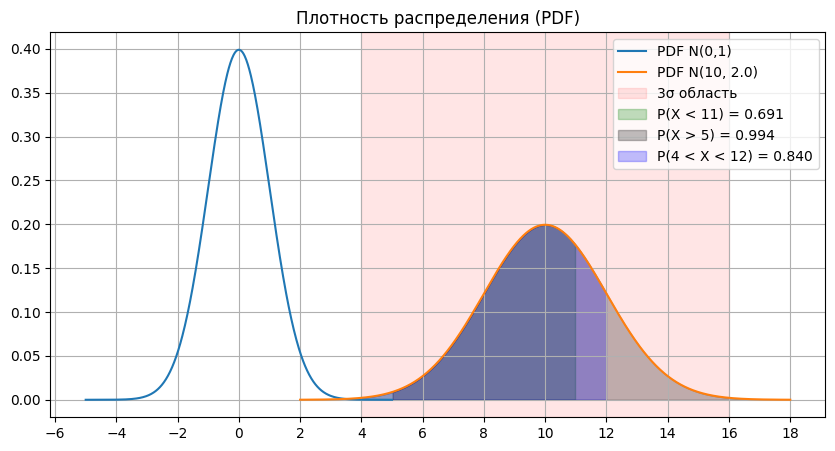

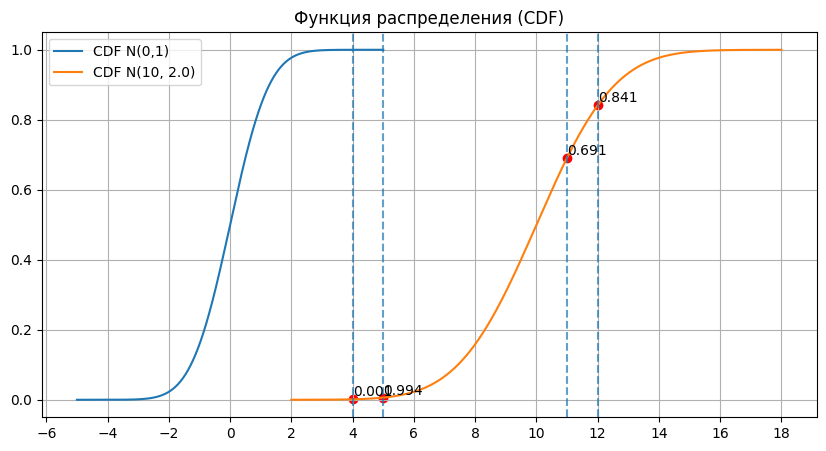

In [4]:
data = normal_distribution(mu, sigma)
plot_normal(data)